# EDA (Exploratory Data Analysis) of the Abalone dataset

**Goal**: predict the age of an abalone, measured as its number of `Rings` (age ≈ Rings + 1.5 years), from physical measurements that are easy to obtain. The traditional method requires cutting the shell, staining it and counting rings under a microscope, which is slow.

This notebook answers the following questions:
1. What does the data look like (types, missing values, duplicates, outliers)?
2. How is the target `Rings` distributed?
3. Which features relate to `Rings`, and how (linearly or not)?
4. What does this imply for the modelling step?

# Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from skrub import TableReport

pd.set_option("display.max_columns", 500)
sns.set_theme(style="whitegrid", palette="deep")

# Data

In [2]:
df = pd.read_csv("../data/abalone.csv")
print(f"Shape: {df.shape}")
df.head(5)

Shape: (4177, 9)


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


| Column | Type | Description |
|---|---|---|
| `Sex` | categorical | M (male), F (female), I (infant) |
| `Length` | continuous | longest shell measurement |
| `Diameter` | continuous | perpendicular to length |
| `Height` | continuous | with meat in shell |
| `Whole weight` | continuous | whole abalone |
| `Shucked weight` | continuous | weight of the meat |
| `Viscera weight` | continuous | gut weight (after bleeding) |
| `Shell weight` | continuous | after being dried |
| `Rings` | integer | **target**, +1.5 gives the age in years |

The continuous measurements have been scaled (lengths divided by 200 in the original data), so the absolute values are not directly interpretable.

# Data quality

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 293.8 KB


In [4]:
feature_cols = df.columns.drop("Rings")
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated features with a different target:", df.duplicated(feature_cols).sum())

Missing values: 0
Duplicated rows: 0
Duplicated features with a different target: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


In [6]:
TableReport(df, verbose=0)

,,,,,,,,,


## Physical consistency

Beyond missing values, each row must respect a few physical constraints:
- no dimension can be zero;
- `Length` is by definition the longest measurement, so `Diameter` cannot exceed it;
- the shucked, viscera and shell weights are parts of the abalone, so none of them can exceed `Whole weight`;
- an abalone shell is flat: `Height` is around a quarter of `Length`. A ratio far outside this range is a typo.

In [7]:
height_ratio = df["Height"] / df["Length"]
height_ratio.describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999])

count    4177.000000
mean        0.264728
std         0.048887
min         0.000000
0.1%        0.121879
1%          0.188235
50%         0.261905
99%         0.356605
99.9%       0.440172
max         2.483516
dtype: float64

In [8]:
part_weights = ["Shucked weight", "Viscera weight", "Shell weight"]

checks = pd.DataFrame(
    {
        "zero dimension": (df[["Length", "Diameter", "Height"]] == 0).any(axis=1),
        "Diameter > Length": df["Diameter"] > df["Length"],
        "part weight > Whole weight": (
            df[part_weights].gt(df["Whole weight"], axis=0).any(axis=1)
        ),
        "Height / Length outside [0.05, 0.6]": ~height_ratio.between(0.05, 0.6),
    }
)
invalid = checks.any(axis=1)
print(checks.sum().to_string())
print(f"\nInvalid rows: {invalid.sum()} ({invalid.mean():.2%} of the dataset)")

reasons = checks[invalid].apply(lambda row: ", ".join(row.index[row]), axis=1)
df[invalid].assign(reason=reasons)

zero dimension                         2
Diameter > Length                      1
part weight > Whole weight             5
Height / Length outside [0.05, 0.6]    6

Invalid rows: 10 (0.24% of the dataset)


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings,reason
1174,F,0.635,0.495,0.015,1.1565,0.5115,0.3080,0.2885,9,"Height / Length outside [0.05, 0.6]"
1210,I,0.185,0.375,0.120,0.4645,0.1960,0.1045,0.1500,6,"Diameter > Length, Height / Length outside [0...."
1216,I,0.310,0.225,0.070,0.1055,0.4350,0.0150,0.0400,5,part weight > Whole weight
1257,I,0.430,0.340,0.000,0.4280,0.2065,0.0860,0.1150,8,"zero dimension, Height / Length outside [0.05,..."
1417,M,0.705,0.565,0.515,2.2100,1.1075,0.4865,0.5120,10,"Height / Length outside [0.05, 0.6]"
2051,F,0.455,0.355,1.130,0.5940,0.3320,0.1160,0.1335,8,"Height / Length outside [0.05, 0.6]"
2627,I,0.275,0.205,0.070,0.1055,0.4950,0.0190,0.0315,5,part weight > Whole weight
2641,I,0.475,0.365,0.100,0.1315,0.2025,0.0875,0.1230,7,part weight > Whole weight
3086,I,0.355,0.270,0.075,0.2040,0.3045,0.0460,0.0595,7,part weight > Whole weight
3996,I,0.315,0.230,0.000,0.1340,0.0575,0.0285,0.3505,6,"zero dimension, part weight > Whole weight, He..."


In [9]:
# The parts do not include the water and blood lost when shucking, so their sum
# should stay below the whole weight
excess = df[part_weights].sum(axis=1) / df["Whole weight"] - 1
print(f"Sum of the parts > Whole weight: {(excess > 0).sum()} rows")
print(f"Sum of the parts > Whole weight by more than 10%: {(excess > 0.1).sum()} rows")

Sum of the parts > Whole weight: 155 rows
Sum of the parts > Whole weight by more than 10%: 42 rows


In [10]:
df_clean = df[~invalid].reset_index(drop=True)
print(f"Shape after cleaning: {df_clean.shape}")

Shape after cleaning: (4167, 9)


**Conclusions**
- No missing values, no duplicated rows, and no pair of abalones with identical measurements.
- **10 rows (0.24%) are physically impossible** and are removed:
  - 2 rows with `Height` = 0;
  - 1 row with `Diameter` (0.375) twice its `Length` (0.185), probably a typo on `Length`;
  - 5 rows where a part weighs more than the whole abalone (e.g. a shucked weight of 0.495 for a whole weight of 0.1055);
  - 3 rows with an absurd `Height` / `Length` ratio: 1.13 for a length of 0.455 (ratio 2.5), 0.515 for a length of 0.705 (ratio 0.73), and 0.015 for a length of 0.635 (ratio 0.02, probably 0.15). The 1st-99th percentile range of the ratio is [0.19, 0.36], so the [0.05, 0.6] bounds only catch obvious errors.
- 155 rows have parts summing to more than the whole weight, 42 of them by more than 10%. This is more likely measurement noise (weights taken at different times, on small abalones) than typos, so we keep them.
- These rules must be applied in the training pipeline, and the same constraints can be used to validate the API inputs.
- From now on, the analysis is done on `df_clean`.

# Target: `Rings`

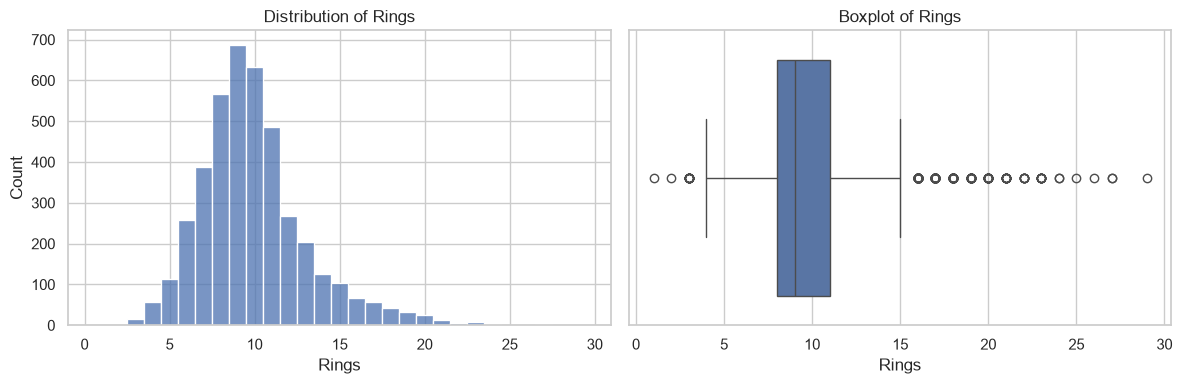

Skewness: 1.11


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean["Rings"], discrete=True, ax=axes[0])
axes[0].set_title("Distribution of Rings")
sns.boxplot(x=df_clean["Rings"], ax=axes[1])
axes[1].set_title("Boxplot of Rings")
plt.tight_layout()
plt.show()
print(f"Skewness: {df['Rings'].skew():.2f}")

In [12]:
rings_counts = df_clean["Rings"].value_counts().sort_index()
print(f"Rings <= 3: {rings_counts.loc[:3].sum()} rows")
print(f"Rings >= 20: {rings_counts.loc[20:].sum()} rows")
print(f"Skewness of log(Rings): {np.log(df_clean['Rings']).skew():.2f}")

Rings <= 3: 17 rows
Rings >= 20: 62 rows
Skewness of log(Rings): -0.24


**Conclusions**
- `Rings` ranges from 1 to 29 with a mean of ~9.9; most values are between 8 and 11.
- The distribution is right-skewed (skewness ≈ 1.1). The tails are very thin: only 17 abalones have 3 rings or fewer, and 62 have 20 or more. A log transformation makes the target almost symmetric (skewness ≈ -0.2).
- RMSE will be dominated by the few old abalones, so MAE is also worth reporting (and easier to interpret, in number of rings).
- With such thin tails, a random split may leave almost no extreme value in the test set: the train/test split should be stratified on binned `Rings`.
- The target is a count, but it can be treated as a regression problem.

# Categorical feature: `Sex`

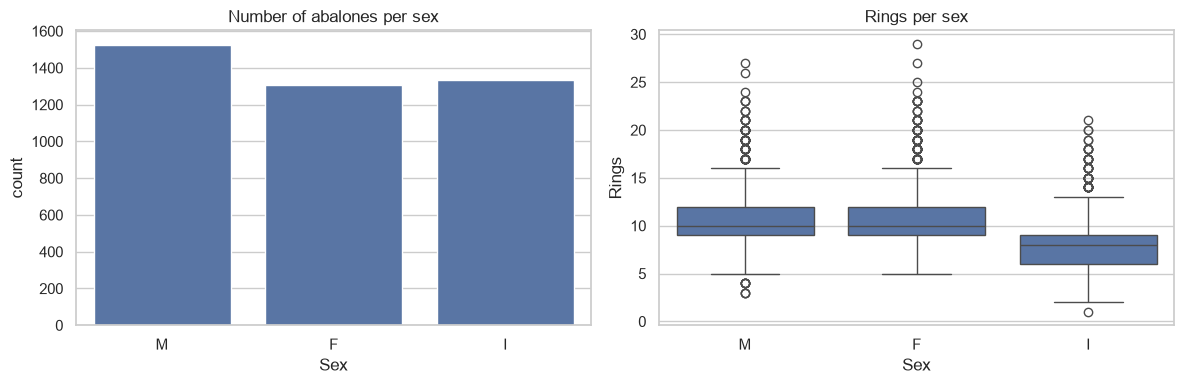

,count,mean,std
Sex,,,
F,1305,11.133333,3.104865
I,1335,7.898876,2.514329
M,1527,10.705959,3.027287


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_clean, x="Sex", order=["M", "F", "I"], ax=axes[0])
axes[0].set_title("Number of abalones per sex")
sns.boxplot(data=df_clean, x="Sex", y="Rings", order=["M", "F", "I"], ax=axes[1])
axes[1].set_title("Rings per sex")
plt.tight_layout()
plt.show()
df_clean.groupby("Sex")["Rings"].agg(["count", "mean", "std"])

In [14]:
# Mean Rings per sex, for abalones of similar length
length_bins = pd.cut(df_clean["Length"], [0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.9])
df_clean.pivot_table(
    index=length_bins, columns="Sex", values="Rings", aggfunc="mean", observed=True
).round(1)

Sex,F,I,M
Length,,,
"(0.0, 0.3]",5.3,5.1,5.7
"(0.3, 0.4]",8.5,6.8,8.6
"(0.4, 0.5]",10.6,8.2,9.8
"(0.5, 0.6]",11.0,9.7,10.9
"(0.6, 0.7]",11.6,11.9,11.4
"(0.7, 0.9]",12.1,10.0,12.0


**Conclusions**
- The three classes are well balanced.
- Infants (`I`) have clearly fewer rings (~7.9) than males and females (~10.7 and ~11.1), which is expected since they are younger.
- This is not only a size effect: **at equal length, infants are younger** (e.g. ~8.2 rings for a length in (0.4, 0.5], versus ~10 for adults). `Sex` therefore carries information that the measurements alone do not.
- Males and females are almost indistinguishable in terms of `Rings`: the main information carried by `Sex` is "infant or adult". It must be one-hot encoded for linear models.

# Numerical features

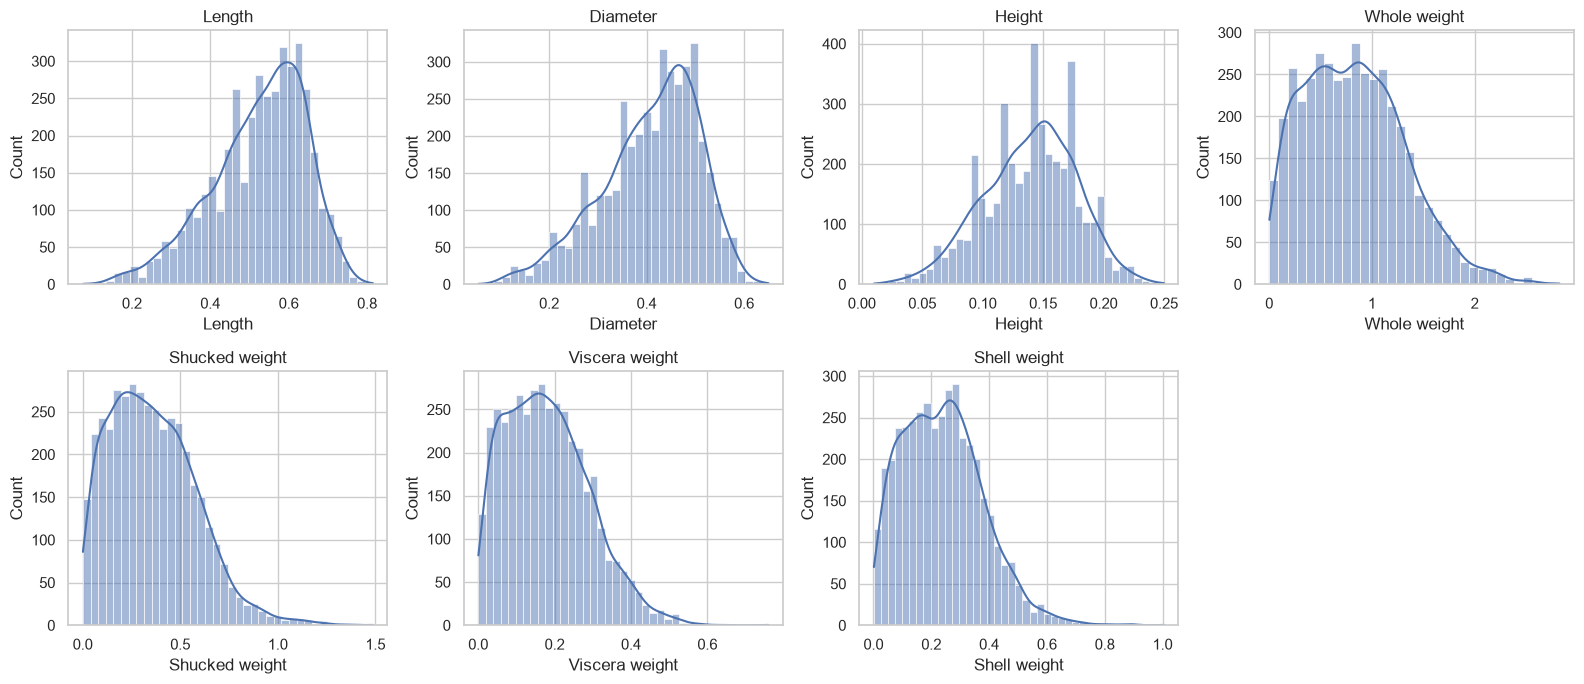

In [15]:
num_cols = df_clean.select_dtypes("number").columns.drop("Rings")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols, strict=False):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

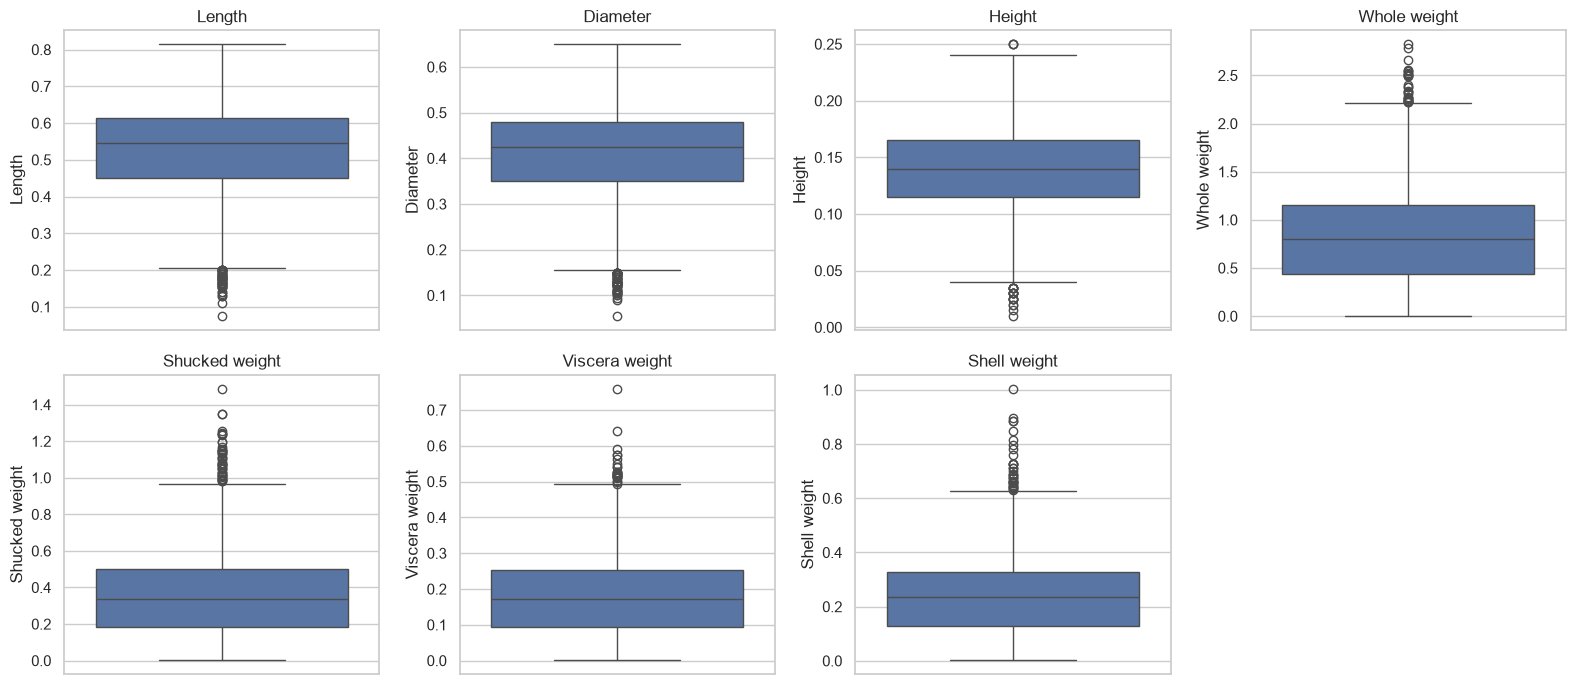

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols, strict=False):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Conclusions**
- `Length` and `Diameter` are left-skewed (few very small abalones), while the weights are right-skewed.
- Once the invalid rows are removed, `Height` ranges from 0.01 to 0.25. The remaining outliers (mostly heavy abalones) are consistent with the other measurements of the same rows, so they are real and are kept.

## Allometry: weight versus length

For a body that grows while keeping the same shape, the weight is proportional to the volume, i.e. to the cube of the length. On a log-log scale this is a straight line of slope 3.

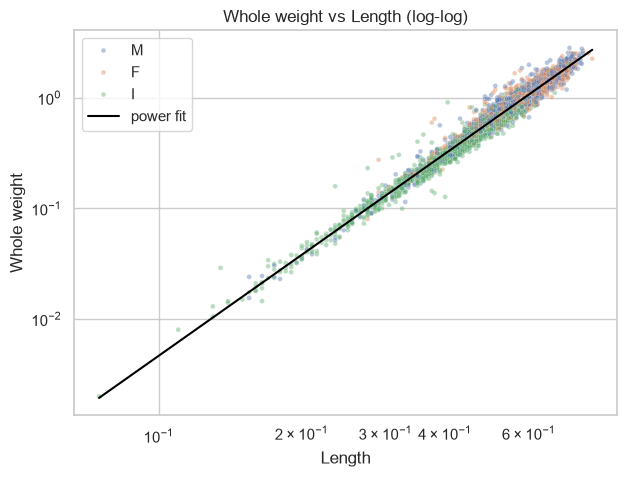

Fitted exponent: 3.04


In [17]:
log_length = np.log(df_clean["Length"])
log_weight = np.log(df_clean["Whole weight"])
slope, intercept = np.polyfit(log_length, log_weight, 1)

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(
    data=df_clean, x="Length", y="Whole weight", hue="Sex", alpha=0.4, s=12, ax=ax
)
x_grid = np.linspace(df_clean["Length"].min(), df_clean["Length"].max(), 100)
ax.plot(x_grid, np.exp(intercept) * x_grid**slope, color="black", label="power fit")
ax.set(xscale="log", yscale="log", title="Whole weight vs Length (log-log)")
ax.legend()
plt.show()
print(f"Fitted exponent: {slope:.2f}")

**Conclusions**
- The fitted exponent is ≈ 3.04: weight scales as length³, as expected for isometric growth. The data is physically consistent once the invalid rows are removed.
- The relationships between features are multiplicative, so **log-transforming the measurements** linearises them. We check below whether this also helps for the target.

# Relationship with the target

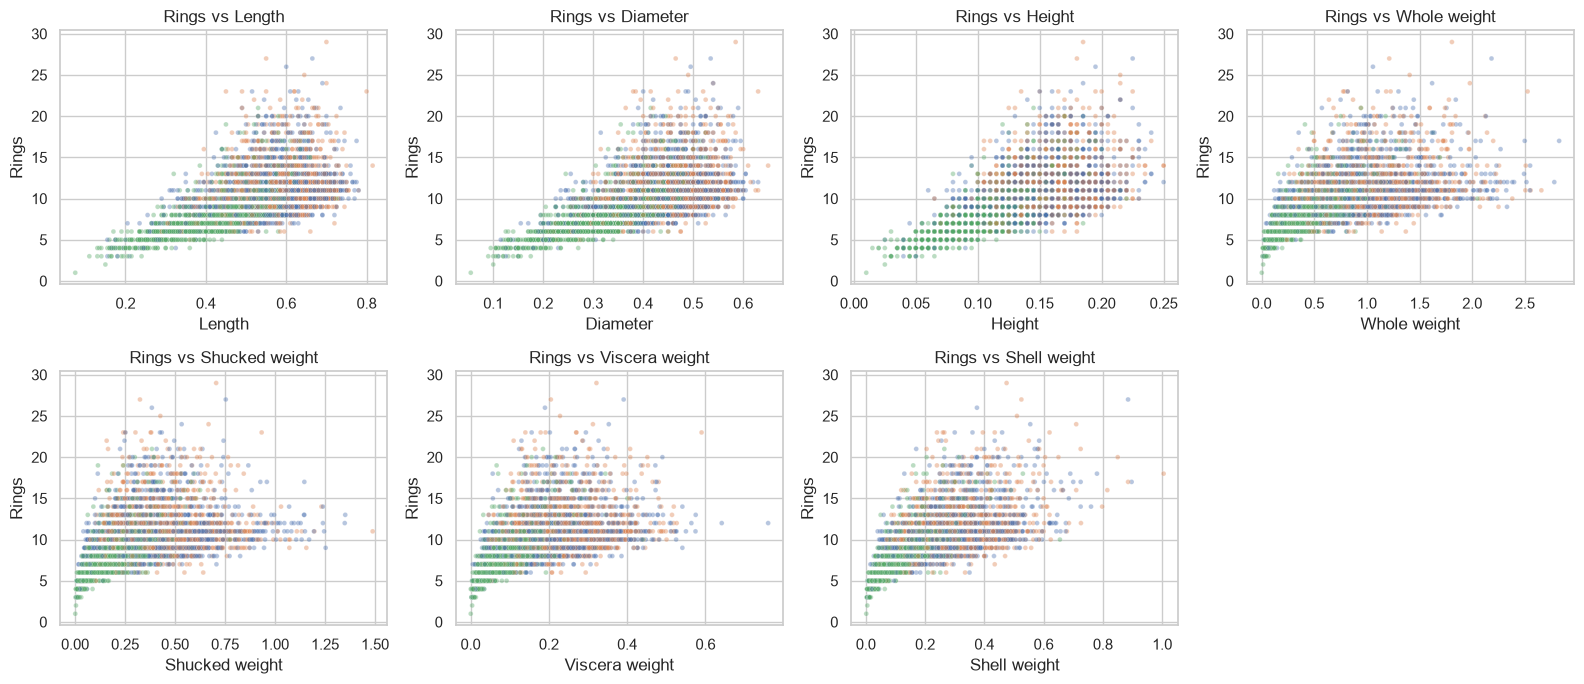

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols, strict=False):
    sns.scatterplot(
        data=df_clean, x=col, y="Rings", hue="Sex", alpha=0.4, s=12, ax=ax, legend=False
    )
    ax.set_title(f"Rings vs {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

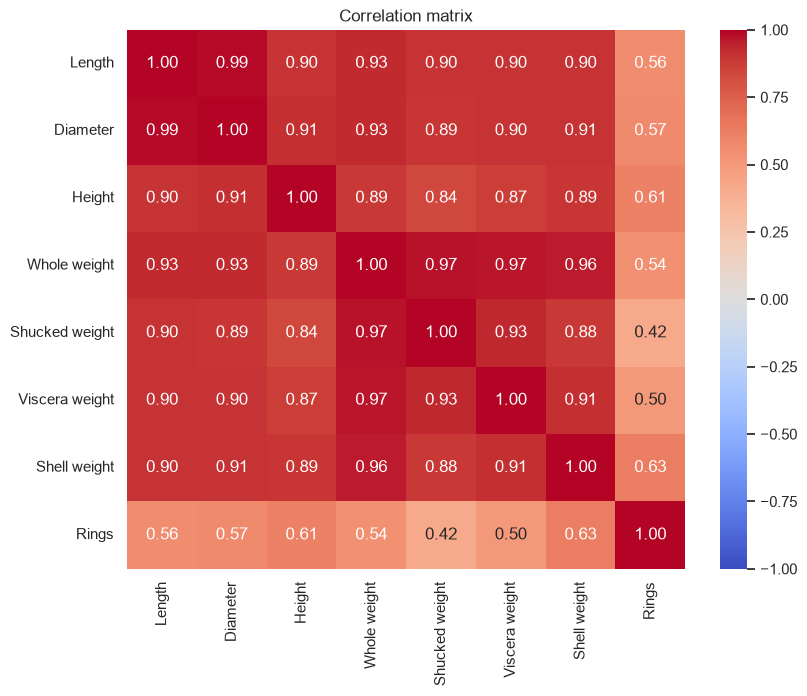

Shell weight      0.627607
Height            0.609943
Diameter          0.573962
Length            0.555755
Whole weight      0.539872
Viscera weight    0.503297
Shucked weight    0.421635
Name: Rings, dtype: float64

In [19]:
corr = df_clean.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()
corr["Rings"].drop("Rings").sort_values(ascending=False)

In [20]:
log_df = np.log(df_clean[num_cols.tolist() + ["Rings"]])
pd.DataFrame(
    {
        "pearson": df_clean[num_cols].corrwith(df_clean["Rings"]),
        "pearson (log-log)": log_df[num_cols].corrwith(log_df["Rings"]),
        "spearman": df_clean[num_cols].corrwith(df_clean["Rings"], method="spearman"),
    }
).sort_values("spearman", ascending=False).round(2)

,pearson,pearson (log-log),spearman
Shell weight,0.63,0.74,0.69
Height,0.61,0.71,0.66
Whole weight,0.54,0.70,0.63
Diameter,0.57,0.69,0.62
Viscera weight,0.50,0.68,0.61
Length,0.56,0.68,0.60
Shucked weight,0.42,0.63,0.54


**Conclusions**
- Every feature is positively correlated with `Rings`; `Shell weight` (0.63) is the strongest. `Height` goes from 0.56 to 0.61 once its invalid values are removed.
- The relationship is **not linear**: abalones stop growing in size as they age, so `Rings` varies a lot for a given size, especially for large abalones (the scatter fans out). The Spearman (rank) correlation is higher than the Pearson one for every feature, which confirms a monotonic but non-linear link. Taking the log of both the features and the target raises the linear correlation further (0.74 for `Shell weight`).
- The features are **strongly collinear** (`Length` and `Diameter` ≈ 0.99, the four weights between 0.88 and 0.97). A plain linear regression will work but its coefficients will be unstable; regularisation (Ridge) or tree-based models can help.

## Infants versus adults

In [21]:
age_group = df_clean["Sex"].eq("I").map({True: "infant", False: "adult"})
pd.DataFrame(
    {
        group: group_df[num_cols].corrwith(group_df["Rings"])
        for group, group_df in df_clean.groupby(age_group)
    }
).round(2)

,adult,infant
Length,0.31,0.69
Diameter,0.34,0.69
Height,0.40,0.72
Whole weight,0.33,0.70
Shucked weight,0.17,0.63
Viscera weight,0.28,0.67
Shell weight,0.47,0.73


In [22]:
# Spread of Rings for increasing sizes
shell_weight_bins = pd.qcut(df_clean["Shell weight"], 5)
df_clean.groupby(shell_weight_bins, observed=True)["Rings"].agg(["mean", "std"]).round(
    2
)

,mean,std
Shell weight,,
"(0.0005, 0.11]",6.74,1.83
"(0.11, 0.19]",9.02,2.14
"(0.19, 0.27]",10.40,2.67
"(0.27, 0.352]",11.07,2.57
"(0.352, 1.005]",12.54,3.32


**Conclusions**
- The measurements predict age **much better for infants than for adults**: the correlation with `Shell weight` is 0.73 for infants and only 0.47 for adults (0.17 versus 0.63 for `Shucked weight`). Once an abalone is mature, its growth slows down and its size says little about its age.
- The spread of `Rings` grows with the size (standard deviation from 1.8 in the lightest fifth to 3.3 in the heaviest): the noise is heteroscedastic, so the errors will be larger on large, old abalones.
- The effect of the measurements depends on `Sex`: a linear model needs interaction terms (`Sex` × features), whereas tree-based models capture this naturally.

## Composition of the weight

In [23]:
weight_ratios = df_clean[part_weights].div(df_clean["Whole weight"], axis=0)
weight_ratios.columns = [f"{col} / Whole weight" for col in part_weights]
weight_ratios.corrwith(df_clean["Rings"]).round(2)

Shucked weight / Whole weight   -0.35
Viscera weight / Whole weight   -0.07
Shell weight / Whole weight      0.17
dtype: float64

**Conclusions**
- At equal total weight, abalones with **more meat are younger** (correlation -0.35 between `Shucked weight / Whole weight` and `Rings`), while the share of the shell slightly increases with age (0.17).
- This explains why a linear model usually gives a negative coefficient to `Shucked weight` despite its positive correlation with `Rings`. These ratios are cheap candidate features for the model.

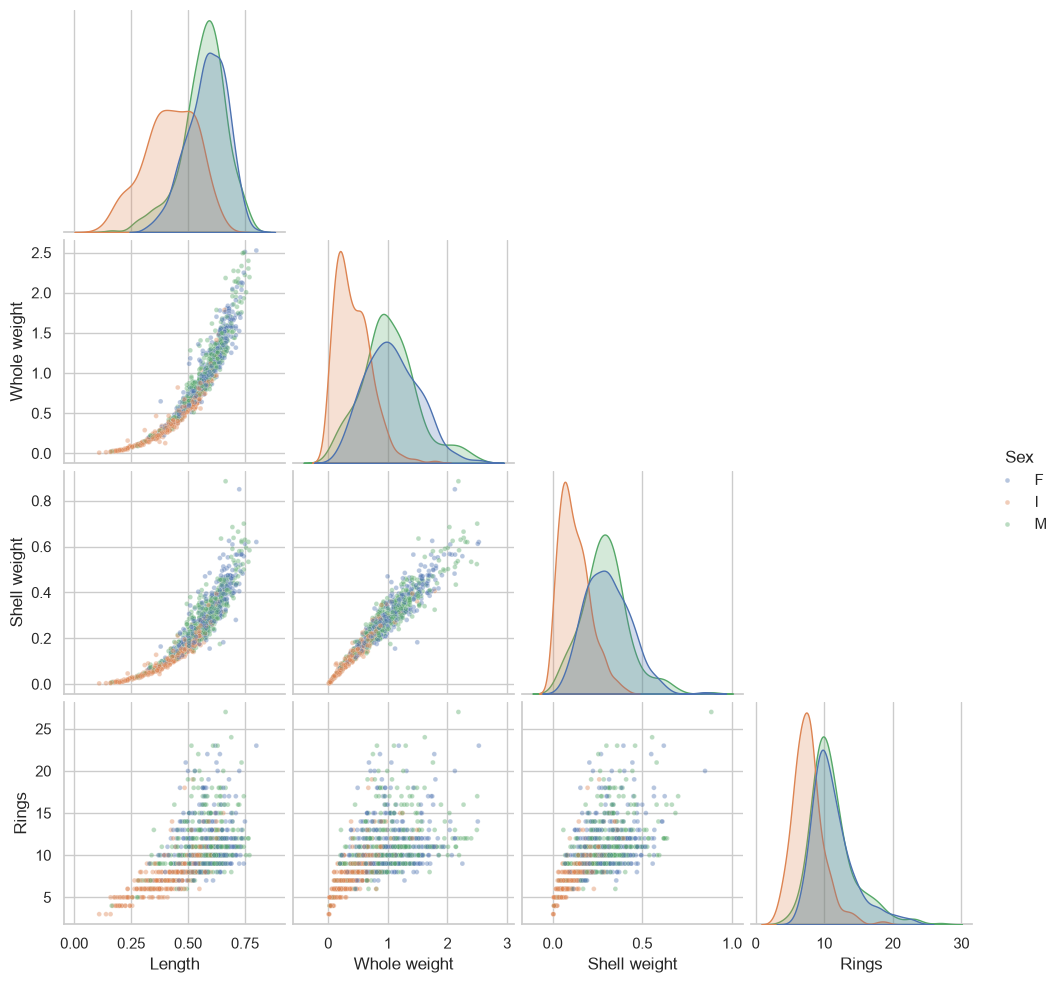

In [24]:
sns.pairplot(
    df_clean.sample(1000, random_state=42),
    vars=["Length", "Whole weight", "Shell weight", "Rings"],
    hue="Sex",
    plot_kws={"alpha": 0.4, "s": 12},
    corner=True,
)
plt.show()

# Summary and implications for modelling

1. **Cleaning**: remove the 10 physically impossible rows (zero `Height`, `Diameter` > `Length`, a part heavier than the whole abalone, absurd `Height` / `Length` ratio). These rules belong in the training pipeline, and the same constraints can validate the API inputs.
2. **Encoding**: one-hot encode `Sex`. Infants are younger than adults at equal size, so `Sex` adds information beyond the measurements.
3. **Target**: right-skewed with very thin tails. Evaluate with MAE and RMSE, stratify the train/test split on binned `Rings`, and test a `log(Rings)` transformation.
4. **Features**: strongly collinear, with a monotonic but non-linear link to the target. Log-transforming the measurements linearises the relationships, and the weight ratios (especially `Shucked weight / Whole weight`) are promising engineered features.
5. **Models**: start with a linear model as a baseline (ideally on log features), then try Ridge or tree-based models (e.g. RandomForest, GradientBoosting), which capture the `Sex` interactions without manual feature engineering.
6. **Expectations**: the signal is limited, especially for adults (correlation ≈ 0.47 at best) and the noise grows with age, so errors will remain noticeable for old abalones.